# 06 · Machine learning (2/3): predicting the **level** - classification

Notebook 05 predicted a *number*. Commuters, though, want a *label*: **Quiet, Moderate or Busy**. Predicting a category is called **classification**.

**Models you will meet:** `Logistic Regression -> KNN -> SVM (SVC) -> Naive Bayes -> Decision Tree -> Random Forest -> Gradient Boosting`

**How we score classification (on hidden data):**
- **Accuracy** - share of correct answers. Misleading when one class is much more common.
- **Balanced accuracy** - the average of the recall of each class (fair to rare classes).
- **Macro-F1** - balance between *precision* (when I say "Busy", how often is it?) and *recall* (of all truly Busy cells, how many did I find?), averaged over classes.
- **Confusion matrix** - a table of right and wrong answers per class.

In [1]:
# --- Setup: run this cell first ---------------------------------------------------------------
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))        # lets the notebook find config.py and the src/ folder
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import config
from src import db

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 30, "display.width", 140)

print("Data mode:", config.MODE.upper(), "| database:", config.DB_NAME if config.USE_MYSQL else "SQLite file")

import time, joblib
from sklearn.model_selection import train_test_split, GroupShuffleSplit, GroupKFold, cross_val_score, GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, confusion_matrix, classification_report
from src import ml_features as mf
from src.common import LEVEL_LABEL

Data mode: REAL | database: SQLite file


## 1. Data and target
Same dataset and features as notebook 05. The target is now the **level**: a stretch-hour is *Quiet* if its crowd index is in the lowest 50% of Delhi, *Moderate* in the next 35%, *Busy* in the top 15%.
(Those percentile cut-offs are in `config.LEVEL_CUTS`.) Because the cut-offs are percentiles, the classes are naturally **imbalanced**: Busy is rare.

In [2]:
engine = db.get_engine()
ds = mf.build_ml_dataset(db.read_table("crowd_hourly_cells", engine), db.read_table("route_patterns", engine), db.read_table("route_attrs", engine))
S = ds.sample(config.ML_SAMPLE_ROWS, random_state=config.RANDOM_STATE).reset_index(drop=True)
X, y, groups = S[mf.FEATURES], S["level"], S["route_n"]
CLASSES = ["low", "medium", "high"]; NAMES = [LEVEL_LABEL[c] for c in CLASSES]
print((y.value_counts(normalize=True).reindex(CLASSES) * 100).round(1).rename(index=LEVEL_LABEL).to_string())

tr_r, te_r = train_test_split(S.index, test_size=0.2, random_state=config.RANDOM_STATE, stratify=y)       # stratify = keep class shares equal in both parts
tr_g, te_g = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=config.RANDOM_STATE).split(S, groups=groups))
splits = {"random": (tr_r, te_r), "unseen routes": (tr_g, te_g)}

level
Quiet       49.0
Moderate    35.5
Busy        15.4


In [3]:
results, fitted = [], {}
def run(name, make_model):
    for split, (tr, te) in splits.items():
        m = make_model(); t0 = time.time(); m.fit(X.loc[tr], y.loc[tr]); secs = time.time() - t0
        p = m.predict(X.loc[te])
        results.append(dict(model=name, split=split, accuracy=accuracy_score(y.loc[te], p), balanced_acc=balanced_accuracy_score(y.loc[te], p),
                            macro_F1=f1_score(y.loc[te], p, average="macro"), fit_seconds=secs))
        if split == "random": fitted[name] = m
    return fitted[name]

run("Baseline (always 'Quiet')", lambda: DummyClassifier(strategy="most_frequent"))
pd.DataFrame(results).round(3)

,model,split,accuracy,balanced_acc,macro_F1,fit_seconds
0,Baseline (always 'Quiet'),random,0.490,0.333,0.219,0.007
1,Baseline (always 'Quiet'),unseen routes,0.509,0.333,0.225,0.006


The lazy baseline already scores ~50% **accuracy** by always saying "Quiet" - yet its **balanced accuracy** is only 33%. This is why accuracy alone can fool you.

## 2. The models

### 2.1 Logistic Regression - despite the name, a classifier
Computes a weighted sum of features (like linear regression) and squashes it into **probabilities** for each class. Fast, explainable, a strong first model.
*Real-life example: a bank estimating the probability that a loan will be repaid.* `class_weight="balanced"` gives rare classes more importance.

In [4]:
logit = run("Logistic Regression", lambda: make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight="balanced")))
pd.DataFrame(results).round(3).tail(2)

,model,split,accuracy,balanced_acc,macro_F1,fit_seconds
2,Logistic Regression,random,0.492,0.496,0.459,0.056
3,Logistic Regression,unseen routes,0.502,0.489,0.454,0.054


### 2.2 KNN classifier - majority vote of the neighbours
Find the `K` most similar stretches and let them **vote** on the level. *Real-life example: judging a restaurant by what its 10 nearest similar restaurants are rated.*
We will tune K with `GridSearchCV` in section 4.

In [5]:
knn = run("KNN (K=15)", lambda: make_pipeline(StandardScaler(), KNeighborsClassifier(15)))

### 2.3 SVM (SVC) - the widest possible street between classes
A Support Vector Machine draws the boundary that leaves the **widest margin** between classes. With the **RBF kernel** the boundary can curve. Strong on medium-sized, clean data; slow on huge data.
*Real-life example: separating spam from normal mail by the cleanest dividing line.*

In [6]:
svc = run("SVM (SVC, RBF kernel)", lambda: make_pipeline(StandardScaler(), SVC(C=3, class_weight="balanced")))

### 2.4 Naive Bayes - probability with a simplifying assumption
Uses Bayes' rule and pretends features are independent given the class ("naive"). Extremely fast, needs little data; weaker when features are strongly linked (ours are).
*Real-life example: classic spam filters multiply the probabilities of each word.*

In [7]:
nb = run("Naive Bayes (Gaussian)", lambda: GaussianNB())

### 2.5 Decision Tree, 2.6 Random Forest, 2.7 Gradient Boosting
The same ideas as in notebook 05, now voting for a **class** instead of averaging a number: a flow-chart of questions; a crowd of trees; trees that fix each other's mistakes.

In [8]:
tree = run("Decision Tree (depth 8)", lambda: DecisionTreeClassifier(max_depth=8, class_weight="balanced", random_state=config.RANDOM_STATE))
rf = run("Random Forest", lambda: RandomForestClassifier(n_estimators=200, min_samples_leaf=3, class_weight="balanced", n_jobs=-1, random_state=config.RANDOM_STATE))
hgb = run("Gradient Boosting", lambda: HistGradientBoostingClassifier(random_state=config.RANDOM_STATE))

## 3. Compare

split,random,unseen routes
model,,
Random Forest,0.609,0.529
Gradient Boosting,0.588,0.525
"SVM (SVC, RBF kernel)",0.544,0.511
Decision Tree (depth 8),0.497,0.478
KNN (K=15),0.495,0.470
Naive Bayes (Gaussian),0.464,0.452
Logistic Regression,0.459,0.454
Baseline (always 'Quiet'),0.219,0.225


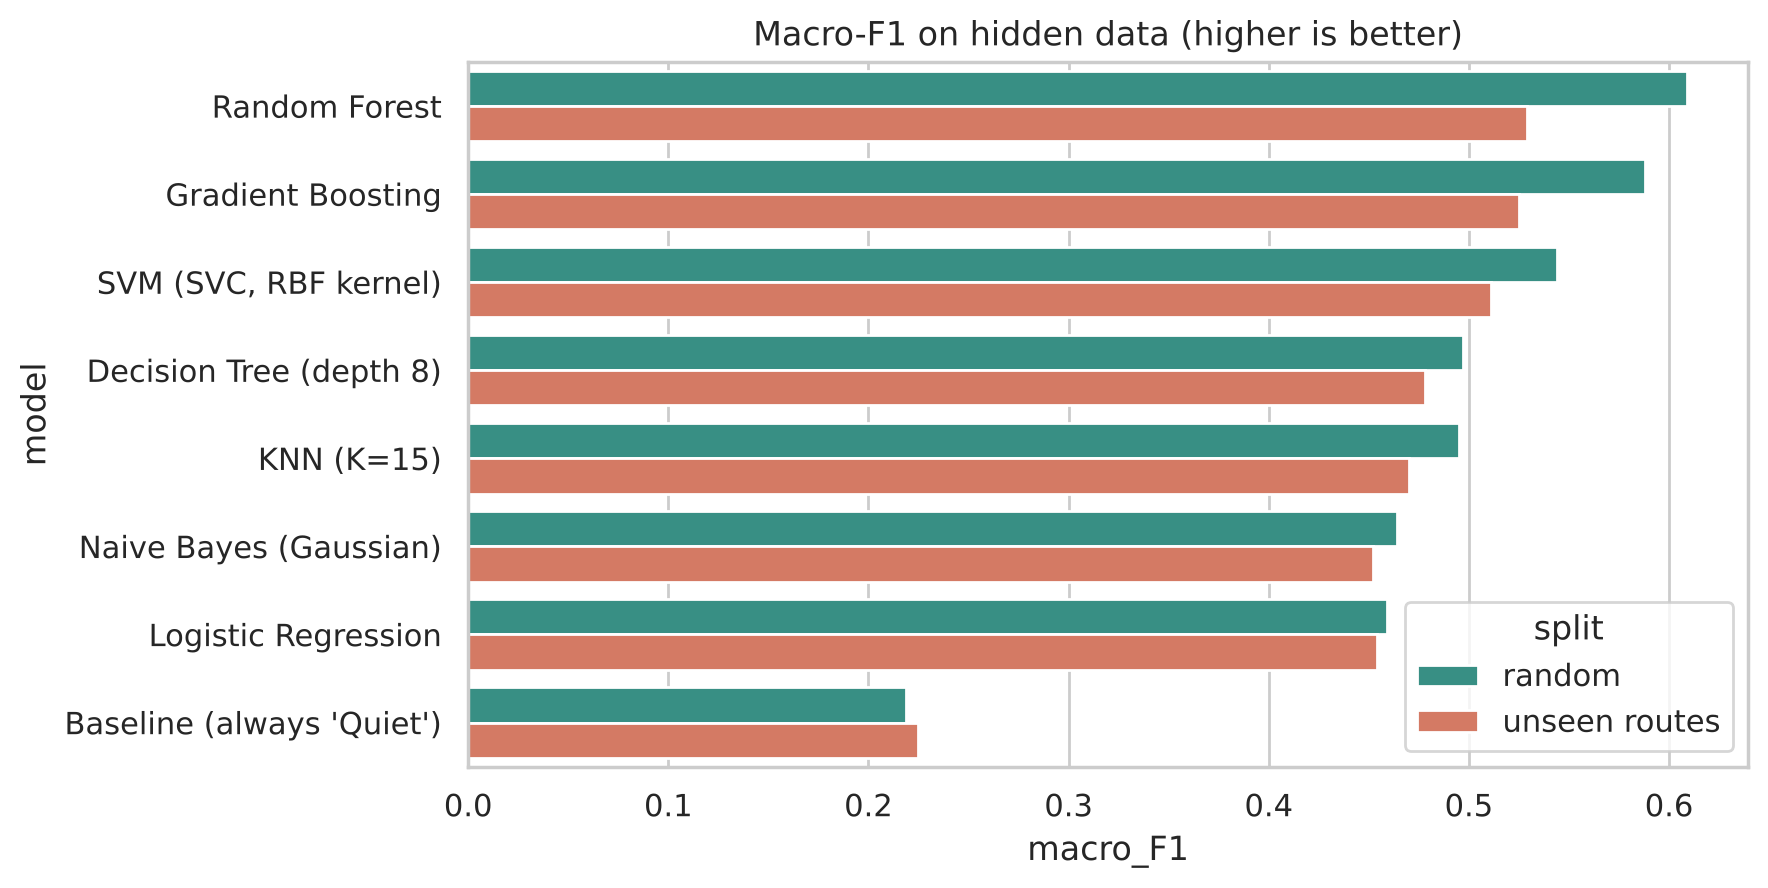

,accuracy,balanced_acc,macro_F1,fit_seconds
model,,,,
Random Forest,0.640,0.622,0.609,3.120
Gradient Boosting,0.642,0.576,0.588,0.668
"SVM (SVC, RBF kernel)",0.573,0.575,0.544,9.167
Decision Tree (depth 8),0.530,0.521,0.497,0.080
KNN (K=15),0.557,0.491,0.495,0.033
Naive Bayes (Gaussian),0.520,0.459,0.464,0.019
Logistic Regression,0.492,0.496,0.459,0.056
Baseline (always 'Quiet'),0.490,0.333,0.219,0.007


In [9]:
res = pd.DataFrame(results).round(3)
wide = res.pivot(index="model", columns="split", values="macro_F1").sort_values("random", ascending=False)
display(wide)
plt.figure(figsize=(9, 4.6)); sns.barplot(data=res, y="model", x="macro_F1", hue="split", order=wide.index, palette=["#2a9d8f", "#e76f51"])
plt.title("Macro-F1 on hidden data (higher is better)"); plt.tight_layout(); plt.savefig(config.FIG / "06_model_comparison.png", dpi=130); plt.show()
res[res.split == "random"].set_index("model").loc[wide.index][["accuracy", "balanced_acc", "macro_F1", "fit_seconds"]]

**What to notice:** the same pattern as in regression - tree-based models lead, simple models trail, and every model drops when it meets routes it has never seen.
Compare **accuracy** and **balanced accuracy**: the baseline's accuracy looked fine, but it never finds a Busy stretch.

## 4. Cross-validation and GridSearchCV

In [10]:
gkf = GroupKFold(n_splits=5)
cv_rows = []
for name, m in {"Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight="balanced")),
                "Random Forest": RandomForestClassifier(n_estimators=100, min_samples_leaf=3, class_weight="balanced", n_jobs=-1, random_state=config.RANDOM_STATE),
                "Gradient Boosting": HistGradientBoostingClassifier(random_state=config.RANDOM_STATE)}.items():
    sc = cross_val_score(m, X, y, cv=gkf, groups=groups, scoring="f1_macro")
    cv_rows.append(dict(model=name, mean_macro_F1=sc.mean(), std=sc.std(), folds=np.round(sc, 2).tolist()))
cv = pd.DataFrame(cv_rows).round(3); cv

,model,mean_macro_F1,std,folds
0,Logistic Regression,0.453,0.009,"[0.46, 0.47, 0.45, 0.45, 0.44]"
1,Random Forest,0.545,0.009,"[0.56, 0.54, 0.54, 0.53, 0.54]"
2,Gradient Boosting,0.527,0.012,"[0.54, 0.54, 0.53, 0.51, 0.52]"


In [11]:
tr, te = splits["unseen routes"]
grid = GridSearchCV(make_pipeline(StandardScaler(), KNeighborsClassifier()),
                    param_grid={"kneighborsclassifier__n_neighbors": [5, 10, 20, 40], "kneighborsclassifier__weights": ["uniform", "distance"]},
                    cv=GroupKFold(n_splits=3), scoring="f1_macro", n_jobs=-1)
grid.fit(X.loc[tr], y.loc[tr], groups=groups.loc[tr])
print("Best KNN settings:", grid.best_params_)
print("Macro-F1 on the HIDDEN routes: %.3f" % f1_score(y.loc[te], grid.predict(X.loc[te]), average="macro"))

Best KNN settings: {'kneighborsclassifier__n_neighbors': 10, 'kneighborsclassifier__weights': 'distance'}


Macro-F1 on the HIDDEN routes: 0.474


## 5. Where does the best model go wrong?
A **confusion matrix**: rows = the truth, columns = the model's answer. A perfect model has numbers only on the diagonal.

Best model on unseen routes: Random Forest


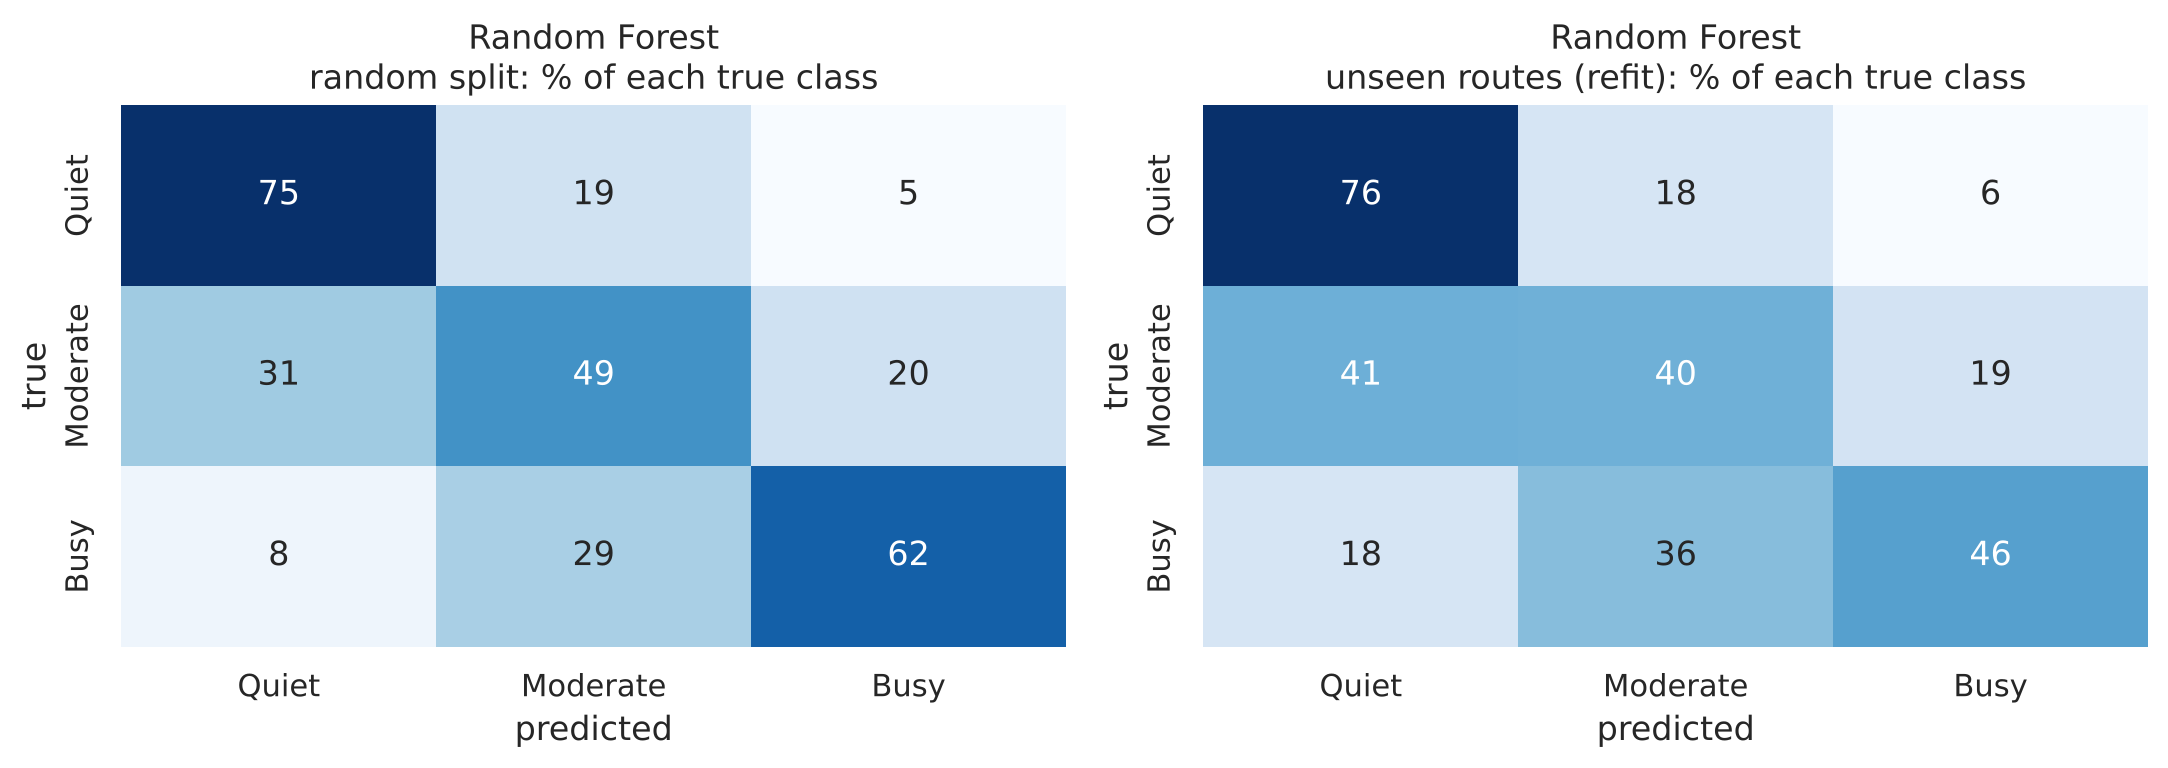

              precision    recall  f1-score   support

       Quiet       0.75      0.75      0.75      1962
    Moderate       0.56      0.49      0.52      1422
        Busy       0.50      0.62      0.55       616

    accuracy                           0.64      4000
   macro avg       0.60      0.62      0.61      4000
weighted avg       0.64      0.64      0.64      4000

Serious mistakes (Quiet predicted as Busy or the other way round): 4.0% of test cells


In [12]:
best = res[res.split == "unseen routes"].sort_values("macro_F1", ascending=False).iloc[0].model
print("Best model on unseen routes:", best)
m = fitted[best]
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a, (split, title) in zip(ax, [("random", "random split"), ("unseen routes", "unseen routes (refit)")]):
    tr, te = splits[split]
    mm = m if split == "random" else __import__("sklearn.base", fromlist=["clone"]).clone(m).fit(X.loc[tr], y.loc[tr])
    cm = confusion_matrix(y.loc[te], mm.predict(X.loc[te]), labels=CLASSES, normalize="true") * 100
    sns.heatmap(pd.DataFrame(cm, index=NAMES, columns=NAMES), annot=True, fmt=".0f", cmap="Blues", cbar=False, ax=a)
    a.set_title(f"{best}\n{title}: % of each true class"); a.set_ylabel("true"); a.set_xlabel("predicted")
plt.tight_layout(); plt.savefig(config.FIG / "06_confusion.png", dpi=130); plt.show()
tr, te = splits["random"]; p = m.predict(X.loc[te])
print(classification_report(y.loc[te], p, labels=CLASSES, target_names=NAMES, digits=2))
far = ((y.loc[te] == "low") & (p == "high")) | ((y.loc[te] == "high") & (p == "low"))
print("Serious mistakes (Quiet predicted as Busy or the other way round): %.1f%% of test cells" % (far.mean() * 100))

Most mistakes are between **neighbouring** levels (Quiet vs Moderate, Moderate vs Busy), which is a mild error for a commuter. Quiet-vs-Busy confusions are rare.
The **Busy** class (the rare one) is the hardest - exactly the class a commuter cares about.

## 6. Save results and the best classifier for the app

In [13]:
db.save_table(res, "ml_classification_results", engine)
db.save_table(cv.assign(folds=cv.folds.astype(str)), "ml_classification_cv", engine)
final = HistGradientBoostingClassifier(random_state=config.RANDOM_STATE).fit(X, y)
(config.OUT / "models").mkdir(exist_ok=True)
joblib.dump({"model": final, "features": mf.FEATURES, "classes": list(final.classes_)}, config.OUT / "models" / "best_classifier.joblib")
import json
(config.OUT / "06_classification_results.json").write_text(json.dumps({"best_on_unseen_routes": best, "table": res.to_dict("records"), "cv": cv.drop(columns="folds").to_dict("records")}, indent=2, default=float))
print("saved: database table ml_classification_results, outputs/models/best_classifier.joblib")

saved: database table ml_classification_results, outputs/models/best_classifier.joblib


## Summary
| Lesson | Where |
|---|---|
| Accuracy can mislead with imbalanced classes; use **balanced accuracy / macro-F1** | Sections 1, 3 |
| **Confusion matrix** shows *which* mistakes a model makes | Section 5 |
| **Probabilities** (Logistic Regression) vs **votes** (KNN) vs **margins** (SVM) | Section 2 |
| Cross-validation and GridSearchCV | Section 4 |

**Next:** `07_clustering_pca.ipynb` - no target at all: can the computer *discover* groups of similar routes by itself?